# Decoding Visual Category Representations from fMRI Activity Using Multi-Voxel Pattern Analysis

Functional MRI measures brain activity indirectly through the BOLD signal, a blood-oxygenation change that peaks a few seconds after neural activity. Multi-voxel pattern analysis (MVPA) treats the pattern across many voxels as a signature that a classifier can learn to decode. This approach comes from work showing that ventral temporal cortex represents categories such as faces and places in distributed patterns.

### Objective
The notebook tests whether the category a person viewed (face, place or object) can be predicted from their fMRI data alone. It uses one subject (sub-01) from OpenNeuro ds001497. For each trial it averages the BOLD signal 4–10 seconds after onset, applies a brain mask, and trains a linear SVM. Evaluation is leave-one-run-out cross-validation across six runs, compared against the 33% chance level.

In [ ]:
!pip install nilearn pandas scikit-learn awscli -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 71.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 5.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


## 2. Download data

Downloads the six BOLD runs and their event files for sub-01 from the public OpenNeuro S3 bucket.

In [ ]:
import subprocess, os

os.makedirs('/content/ds001497/sub-01/func/', exist_ok=True)

base_s3  = 's3://openneuro.org/ds001497/sub-01/func'
base_local = '/content/ds001497/sub-01/func'
files_to_fetch = []

for run in range(1, 7):
    files_to_fetch += [
        f'sub-01_task-LTM_run-{run}_bold.nii.gz',
        f'sub-01_task-LTM_run-{run}_events.tsv',
    ]

for fname in files_to_fetch:
    src  = f'{base_s3}/{fname}'
    dest = f'{base_local}/{fname}'
    print(f'Downloading {fname}...')
    result = subprocess.run(
        ['aws', 's3', 'cp', '--no-sign-request', src, dest],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        print(f'  ERROR: {result.stderr.strip()}')
    else:
        size_mb = os.path.getsize(dest) / 1e6
        print(f'  OK  ({size_mb:.1f} MB)')

  OK  (39.8 MB)
  OK  (0.0 MB)
  OK  (39.8 MB)
  OK  (0.0 MB)
  OK  (39.6 MB)
  OK  (0.0 MB)
  OK  (39.8 MB)
  OK  (0.0 MB)
  OK  (39.9 MB)
  OK  (0.0 MB)
  OK  (39.8 MB)
  OK  (0.0 MB)


## 3. Verify downloads

In [ ]:
import glob

files = sorted(glob.glob('/content/ds001497/sub-01/func/*'))
print(f'{len(files)} files downloaded:\n')
for f in files:
    print(f'  {os.path.basename(f)}  ({os.path.getsize(f)/1e6:.1f} MB)')

assert len(files) == 12, f"Expected 12 files, got {len(files)}. Re-run Cell 2."
print("\nAll files present. Ready to proceed.")

12 files downloaded:

  sub-01_task-LTM_run-1_bold.nii.gz  (39.8 MB)
  sub-01_task-LTM_run-1_events.tsv  (0.0 MB)
  sub-01_task-LTM_run-2_bold.nii.gz  (39.8 MB)
  sub-01_task-LTM_run-2_events.tsv  (0.0 MB)
  sub-01_task-LTM_run-3_bold.nii.gz  (39.6 MB)
  sub-01_task-LTM_run-3_events.tsv  (0.0 MB)
  sub-01_task-LTM_run-4_bold.nii.gz  (39.8 MB)
  sub-01_task-LTM_run-4_events.tsv  (0.0 MB)
  sub-01_task-LTM_run-5_bold.nii.gz  (39.9 MB)
  sub-01_task-LTM_run-5_events.tsv  (0.0 MB)
  sub-01_task-LTM_run-6_bold.nii.gz  (39.8 MB)
  sub-01_task-LTM_run-6_events.tsv  (0.0 MB)

All files present. Ready to proceed.


## 4. Inspect event files


In [ ]:
import pandas as pd

func_dir    = '/content/ds001497/sub-01/func/'
event_files = sorted(glob.glob(func_dir + '*_events.tsv'))

for ef in event_files:
    df = pd.read_csv(ef, sep='\t')
    print(f"=== {os.path.basename(ef)} ===")
    print(f"  Columns      : {list(df.columns)}")
    print(f"  Shape        : {df.shape}")
    if 'trial_type' in df.columns:
        print(f"  trial_types  : {df['trial_type'].unique()}")
        print(f"  NaN rows     : {df['trial_type'].isna().sum()}")
    else:
        print("  WARNING: no 'trial_type' column found")
    print()

=== sub-01_task-LTM_run-1_events.tsv ===
  Columns      : ['onset', 'duration', 'trial_type']
  Shape        : (15, 3)
  trial_types  : ['object' 'face' 'place']
  NaN rows     : 0

=== sub-01_task-LTM_run-2_events.tsv ===
  Columns      : ['onset', 'duration', 'trial_type']
  Shape        : (15, 3)
  trial_types  : ['face' 'object' 'place']
  NaN rows     : 0

=== sub-01_task-LTM_run-3_events.tsv ===
  Columns      : ['onset', 'duration', 'trial_type']
  Shape        : (15, 3)
  trial_types  : ['place' 'face' 'object']
  NaN rows     : 0

=== sub-01_task-LTM_run-4_events.tsv ===
  Columns      : ['onset', 'duration', 'trial_type']
  Shape        : (15, 3)
  trial_types  : ['face' 'place' 'object']
  NaN rows     : 0

=== sub-01_task-LTM_run-5_events.tsv ===
  Columns      : ['onset', 'duration', 'trial_type']
  Shape        : (15, 3)
  trial_types  : ['object' 'place' 'face']
  NaN rows     : 0

=== sub-01_task-LTM_run-6_events.tsv ===
  Columns      : ['onset', 'duration', 'trial_typ

## 5. Extract trial features and run MVPA decoding

Average the BOLD signal 4–10 s after each trial onset, mask the brain, and train a linear SVM with leave-one-run-out cross-validation.

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from nilearn.maskers import NiftiMasker
from nilearn import image
from sklearn.svm import LinearSVC
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import classification_report

# ── Parameters ───────────────────────────────────────────────────────────────
TR            = 2.0   # repetition time in seconds (ds001497)
PEAK_START_TR = 2     # start of HRF averaging window (~4s post-onset)
PEAK_END_TR   = 5     # end   of HRF averaging window (~10s post-onset)

# ── Locate runs ───────────────────────────────────────────────────────────────
func_dir = '/content/ds001497/sub-01/func/'
runs     = sorted(glob.glob(func_dir + '*_bold.nii.gz'))
assert len(runs) > 0, f"No BOLD files found in {func_dir}"
print(f"Found {len(runs)} runs")

# ── Extract one mean 3D image per trial across all runs ───────────────────────
trial_imgs = []
labels     = []
run_tags   = []

for run_idx, run_file in enumerate(runs):
    events_file = run_file.replace('_bold.nii.gz', '_events.tsv')
    if not os.path.exists(events_file):
        print(f"WARNING: missing events for {os.path.basename(run_file)}, skipping.")
        continue

    events = pd.read_csv(events_file, sep='\t')
    assert 'trial_type' in events.columns, (
        f"'trial_type' missing in {events_file}. Columns: {list(events.columns)}"
    )

    valid_events = events.dropna(subset=['trial_type']).reset_index(drop=True)
    onset_trs    = np.floor(valid_events['onset'] / TR).astype(int)

    run_img   = image.load_img(run_file)
    total_trs = run_img.shape[-1]
    print(f"  Run {run_idx+1}: {total_trs} volumes | {len(valid_events)} trials | "
          f"conditions: {valid_events['trial_type'].unique()}")

    for onset_tr, label in zip(onset_trs, valid_events['trial_type']):
        start = onset_tr + PEAK_START_TR
        end   = min(onset_tr + PEAK_END_TR, total_trs - 1)
        if start >= total_trs:
            continue
        window  = image.index_img(run_img, list(range(start, end + 1)))
        avg_img = image.mean_img(window)
        trial_imgs.append(avg_img)
        labels.append(label)
        run_tags.append(run_idx)

print(f"\nTotal trials extracted : {len(trial_imgs)}")
print(f"Conditions             : {np.unique(labels)}")
print(f"Trials per condition   : { {c: int(np.sum(np.array(labels)==c)) for c in np.unique(labels)} }")

# ── Concatenate into 4D image ─────────────────────────────────────────────────
all_bold = image.concat_imgs(trial_imgs)
y        = np.array(labels)
groups   = np.array(run_tags)

# ── Mask: produce (n_trials × n_voxels) matrix ────────────────────────────────
print("\nFitting brain mask and extracting voxel matrix...")
masker = NiftiMasker(
    mask_strategy='epi',
    standardize=True,
    memory='nilearn_cache',
    verbose=0
)
X = masker.fit_transform(all_bold)
print(f"Data matrix shape: {X.shape}  (trials × voxels)")

# ── Leave-One-Run-Out cross-validation ────────────────────────────────────────
print("\nRunning Leave-One-Run-Out cross-validation...")
clf = LinearSVC(max_iter=10000, dual=True)
cv  = LeaveOneGroupOut()

accuracies  = []
all_preds   = []
all_true    = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups)):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    fold_acc = np.mean(preds == y_test)
    accuracies.append(fold_acc)
    all_preds.extend(preds)
    all_true.extend(y_test)
    print(f"  Fold {fold+1}: accuracy = {fold_acc*100:.1f}%")

# ── Summary ───────────────────────────────────────────────────────────────────
chance = 100 / len(np.unique(y))
print(f"\n{'='*50}")
print(f"Mean CV Accuracy : {np.mean(accuracies)*100:.2f}%")
print(f"Std  CV Accuracy : {np.std(accuracies)*100:.2f}%")
print(f"Chance level     : {chance:.1f}%  ({len(np.unique(y))} classes)")
print(f"\nAggregated Classification Report (all folds):")
print(classification_report(all_true, all_preds))

Found 6 runs
  Run 1: 195 volumes | 15 trials | conditions: ['object' 'face' 'place']
  Run 2: 195 volumes | 15 trials | conditions: ['face' 'object' 'place']
  Run 3: 195 volumes | 15 trials | conditions: ['place' 'face' 'object']
  Run 4: 195 volumes | 15 trials | conditions: ['face' 'place' 'object']
  Run 5: 195 volumes | 15 trials | conditions: ['object' 'place' 'face']
  Run 6: 195 volumes | 15 trials | conditions: ['object' 'face' 'place']

Total trials extracted : 90
Conditions             : ['face' 'object' 'place']
Trials per condition   : {np.str_('face'): 30, np.str_('object'): 30, np.str_('place'): 30}

Fitting brain mask and extracting voxel matrix...


/tmp/ipykernel_2787/2825713861.py:74: FutureWarning: The 'zscore' strategy incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.14.0, the 'zscore' option will be removed and using standardize=True will fall back to 'zscore_sample'.To avoid this warning, please use 'zscore_sample' instead.
  X = masker.fit_transform(all_bold)


Data matrix shape: (90, 21600)  (trials × voxels)

Running Leave-One-Run-Out cross-validation...
  Fold 1: accuracy = 80.0%
  Fold 2: accuracy = 80.0%
  Fold 3: accuracy = 46.7%
  Fold 4: accuracy = 60.0%
  Fold 5: accuracy = 73.3%
  Fold 6: accuracy = 66.7%

Mean CV Accuracy : 67.78%
Std  CV Accuracy : 11.81%
Chance level     : 33.3%  (3 classes)

Aggregated Classification Report (all folds):
              precision    recall  f1-score   support

        face       0.77      0.90      0.83        30
      object       0.62      0.53      0.57        30
       place       0.62      0.60      0.61        30

    accuracy                           0.68        90
   macro avg       0.67      0.68      0.67        90
weighted avg       0.67      0.68      0.67        90



## 6. Plot decoding accuracy


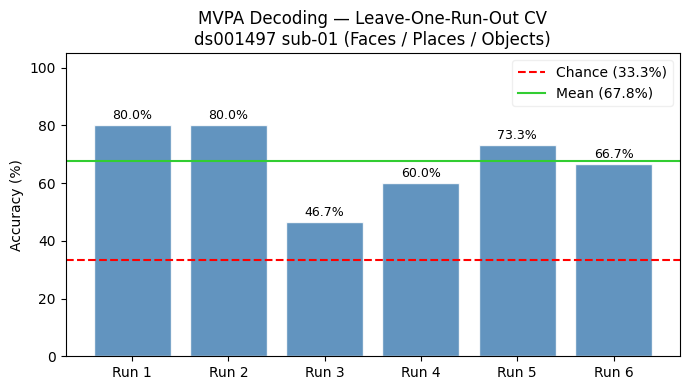

Saved to /content/mvpa_accuracy.png


In [ ]:
import matplotlib.pyplot as plt

chance     = 100 / len(np.unique(y))
fold_names = [f"Run {i+1}" for i in range(len(accuracies))]
accs_pct   = [a * 100 for a in accuracies]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(fold_names, accs_pct, color='steelblue', alpha=0.85, edgecolor='white')

ax.axhline(chance,
           color='red', linestyle='--', linewidth=1.5,
           label=f'Chance ({chance:.1f}%)')
ax.axhline(np.mean(accs_pct),
           color='limegreen', linestyle='-', linewidth=1.5,
           label=f'Mean ({np.mean(accs_pct):.1f}%)')

for bar, acc in zip(bars, accs_pct):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f'{acc:.1f}%', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 105)
ax.set_title('MVPA Decoding — Leave-One-Run-Out CV\nds001497 sub-01 (Faces / Places / Objects)')
ax.legend(framealpha=0.3)
plt.tight_layout()
plt.savefig('/content/mvpa_accuracy.png', dpi=150)
plt.show()
print("Saved to /content/mvpa_accuracy.png")

## 7. Results

Leave-one-run-out cross-validation over 6 runs (90 trials: 30 face, 30 object, 30 place; 21,600 voxels) gave a **mean accuracy of 67.78% ± 11.81% (SD)**, well above the 33.3% chance level for three classes.

| Held-out run | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| Accuracy | 80.0% | 80.0% | 46.7% | 60.0% | 73.3% | 66.7% |

Aggregated classification report across all folds:

| Class | Precision | Recall | F1 |
|---|---|---|---|
| face | 0.77 | 0.90 | 0.83 |
| object | 0.62 | 0.53 | 0.57 |
| place | 0.62 | 0.60 | 0.61 |

Faces were decoded most reliably; objects and places were less well separated. Accuracy varied across runs (lowest for run 3 at 46.7%). These results come from a single subject and no permutation test was run, so they should be read as descriptive rather than as a formal significance test.